# 6주차 실습: 이진 트리 구조 설계 및 순회 — 학생용

## 실습 목표 및 규약
TreeNode/BinaryTree 설계, 재귀 DFS 3종, 반복 전위, 큐 기반 BFS, 높이·노드·리프 수를 구현한다.
- Python 3.8+ / Jupyter 또는 Colab. 위에서 아래 순서로 실행한다.
- 루트 깊이 0, 리프 높이 0, 빈 트리 높이 -1: **간선 수 기준**.
- 일반 이진 트리는 BST가 아니다. 중위 순회가 항상 정렬되는 것은 아니다.
- 이 실습의 구조는 사이클·공유 자식 없는 트리라고 가정한다.
- `BinaryTree(None)`은 빈 트리를 뜻한다. None 값을 가진 루트는 `tree.root = TreeNode(None)`으로 생성한다.


In [1]:
from collections import deque
print("실습 환경 준비 완료")

실습 환경 준비 완료


## Step 1. TreeNode
데이터와 왼쪽/오른쪽 자식 참조를 저장합니다.

In [11]:
class TreeNode:
    def __init__(self, data):
      # TODO: data, left, right 초기화 (자식은 None)
        self.data = data
        self.left = None
        self.right = None

    def __repr__(self):
        return f"TreeNode({self.data!r})"

## Step 2. BinaryTree
전위 NLR / 중위 LNR / 후위 LRN. 재귀는 None에서 종료. 반복 전위는 오른쪽 먼저 push.

In [12]:
class BinaryTree:
    def __init__(self, root_data=None):
        self.root = None if root_data is None else TreeNode(root_data)

    def is_empty(self):
        return self.root is None

    def preorder(self):
        result = []
        def _visit(node):
            if node is None:
                return
            result.append(node.data)
            _visit(node.left)
            _visit(node.right)
        _visit(self.root)
        return result

    def inorder(self):
        result = []
        def _visit(node):
            if node is None:
                return
            _visit(node.left)
            result.append(node.data)
            _visit(node.right)
        _visit(self.root)
        return result

    def postorder(self):
        result = []
        def _visit(node):
            if node is None:
                return
            _visit(node.left)
            _visit(node.right)
            result.append(node.data)
        _visit(self.root)
        return result

    def preorder_iterative(self):
        if self.root is None:
            return []
        result = []
        stack = [self.root]
        while stack:
            curr = stack.pop()
            result.append(curr.data)
            if curr.right is not None:
                stack.append(curr.right)
            if curr.left is not None:
                stack.append(curr.left)
        return result

    def levelorder(self):
        if self.root is None:
            return []
        result = []
        queue = deque([self.root])
        while queue:
            curr = queue.popleft()
            result.append(curr.data)
            if curr.left is not None:
                queue.append(curr.left)
            if curr.right is not None:
                queue.append(curr.right)
        return result

    def height(self):
        def _height(node):
            if node is None:
                return -1
            return 1 + max(_height(node.left), _height(node.right))
        return _height(self.root)

    def count_nodes(self):
        def _count(node):
            if node is None:
                return 0
            return 1 + _count(node.left) + _count(node.right)
        return _count(self.root)

    def count_leaves(self):
        def _leaves(node):
            if node is None:
                return 0
            if node.left is None and node.right is None:
                return 1
            return _leaves(node.left) + _leaves(node.right)
        return _leaves(self.root)

## Step 3. 예시 트리
```text
      A
    /   \
   B     C
  / \     \
 D   E     F
```

In [13]:
tree = BinaryTree("A")
# B,C,D,E,F를 그림과 같이 연결
tree.root.left = TreeNode("B")
tree.root.right = TreeNode("C")
tree.root.left.left = TreeNode("D")
tree.root.left.right = TreeNode("E")
tree.root.right.right = TreeNode("F")

## Step 4. 결과 및 경계 사례 검증

In [14]:
expected = {
    "preorder": ["A", "B", "D", "E", "C", "F"],
    "inorder": ["D", "B", "E", "A", "C", "F"],
    "postorder": ["D", "E", "B", "F", "C", "A"],
    "levelorder": ["A", "B", "C", "D", "E", "F"]
}
for method, answer in expected.items():
    actual = getattr(tree, method)()
    print(method, actual)
    assert actual == answer
assert tree.preorder_iterative() == tree.preorder()
assert (tree.height(), tree.count_nodes(), tree.count_leaves()) == (2, 6, 3)
print("예시 트리 테스트 통과")


preorder ['A', 'B', 'D', 'E', 'C', 'F']
inorder ['D', 'B', 'E', 'A', 'C', 'F']
postorder ['D', 'E', 'B', 'F', 'C', 'A']
levelorder ['A', 'B', 'C', 'D', 'E', 'F']
예시 트리 테스트 통과


In [15]:
for t, sequence, height, leaves in [
    (BinaryTree(), [], -1, 0),
    (BinaryTree("X"), ["X"], 0, 1),
]:
    for method in ["preorder", "inorder", "postorder", "levelorder", "preorder_iterative"]:
        assert getattr(t, method)() == sequence
    assert (t.height(), t.count_nodes(), t.count_leaves()) == (height, len(sequence), leaves)

skew = BinaryTree(1)
skew.root.right = TreeNode(2)
skew.root.right.right = TreeNode(3)
assert skew.preorder() == skew.inorder() == skew.levelorder() == [1, 2, 3]
assert skew.postorder() == [3, 2, 1]
assert skew.preorder_iterative() == [1, 2, 3]
assert (skew.height(), skew.count_nodes(), skew.count_leaves()) == (2, 3, 1)
print("빈 트리 / 단일 노드 / 편향 트리 테스트 통과")


빈 트리 / 단일 노드 / 편향 트리 테스트 통과


## Step 5. VisuAlgo 시각화 및 검증
[VisuAlgo BST](https://visualgo.net/en/bst)는 **BST 시각화**이며 임의의 A~F 이진 트리를 직접 만드는 도구라고 가정하지 않습니다.
1. BST 모드에서 빈 트리에 **4, 2, 6, 1, 3, 7** 순서로 삽입합니다(자동 균형 모드와 구별).
2. A→4, B→2, C→6, D→1, E→3, F→7 대응으로 위 예시와 구조를 비교합니다.
3. 화면에서 제공되는 순회 기능은 애니메이션으로 검증하고, 미지원 순회는 그림 위에 방문 번호를 적어 검증합니다.
4. 아래 코드 결과와 수동 trace를 비교하고 캡처와 설명을 기록하세요. **BST 삽입은 다음 주 내용이며 이번에는 구조 관찰만 합니다.**


In [16]:
numeric = BinaryTree(4)
numeric.root.left = TreeNode(2)
numeric.root.right = TreeNode(6)
numeric.root.left.left = TreeNode(1)
numeric.root.left.right = TreeNode(3)
numeric.root.right.right = TreeNode(7)
assert numeric.preorder() == [4, 2, 1, 3, 6, 7]
assert numeric.inorder() == [1, 2, 3, 4, 6, 7]
assert numeric.postorder() == [1, 3, 2, 7, 6, 4]
assert numeric.levelorder() == [4, 2, 6, 1, 3, 7]
for method in ["preorder", "inorder", "postorder", "levelorder"]:
    print(method, getattr(numeric, method)())


preorder [4, 2, 1, 3, 6, 7]
inorder [1, 2, 3, 4, 6, 7]
postorder [1, 3, 2, 7, 6, 4]
levelorder [4, 2, 6, 1, 3, 7]


## 복잡도 분석
n=노드 수, h=간선 기준 높이, w=최대 레벨 너비.

|연산|시간|보조 공간(출력 제외)|
|---|---|---|
|재귀 DFS 3종 / 반복 전위|O(n)|O(h+1)|
|큐 기반 레벨 순회|O(n)|O(w)|
|높이·노드 수·리프 수|O(n)|O(h+1)|
|완전 트리 구성|O(n)|O(n) 큐 + O(n) 생성 노드|

순회 반환 리스트는 별도 O(n) 공간입니다. 균형 트리는 h=O(log n), 편향 트리는 h=O(n). 깊은 편향 트리의 재귀는 Python 재귀 깊이 제한에 걸릴 수 있습니다. BFS도 깊이별 수집으로 재귀 구현 가능하지만 큐 기반 반복이 자연스럽습니다.


## 제출 과제: 이진 트리 순회 프로그램
1. build_complete_tree(values)를 구현하고 네 가지 순회 결과 출력.
2. 빈/단일/완전/편향 트리 테스트 및 시간·공간 복잡도 설명.
3. 시각화 캡처와 방문 순서 검증 설명 첨부.
4. 개인 GitHub의 Week6 폴더에 노트북/설명 저장. 계획서대로 주당 최소 2회 커밋, 과제 폼에 GitHub 링크 제출.

주의: 아래 TODO를 구현하기 전 학생용 테스트 실패는 정상입니다. 미구현 셀은 무한 반복 대신 NotImplementedError로 즉시 중단합니다.


In [17]:
def build_complete_tree(values):
    tree = BinaryTree()
    if not values:
        return tree

    tree.root = TreeNode(values[0])
    queue = deque([tree.root])
    i = 1
    n = len(values)
    while i < n:
        parent = queue.popleft()
        parent.left = TreeNode(values[i])
        queue.append(parent.left)
        i += 1
        if i < n:
            parent.right = TreeNode(values[i])
            queue.append(parent.right)
            i += 1
    return tree

In [18]:
complete = build_complete_tree([1, 2, 3, 4, 5, 6, 7])
assert complete.preorder() == [1, 2, 4, 5, 3, 6, 7]
assert complete.inorder() == [4, 2, 5, 1, 6, 3, 7]
assert complete.postorder() == [4, 5, 2, 6, 7, 3, 1]
assert complete.levelorder() == [1, 2, 3, 4, 5, 6, 7]
assert complete.preorder_iterative() == complete.preorder()
assert build_complete_tree([]).height() == -1
assert build_complete_tree([9]).levelorder() == [9]
assert build_complete_tree([1, 2, 3, 4]).levelorder() == [1, 2, 3, 4]
assert build_complete_tree([None, 2]).levelorder() == [None, 2]
for method in ["preorder", "inorder", "postorder", "levelorder"]:
    print(method, getattr(complete, method)())
print("과제 테스트 통과")


preorder [1, 2, 4, 5, 3, 6, 7]
inorder [4, 2, 5, 1, 6, 3, 7]
postorder [4, 5, 2, 6, 7, 3, 1]
levelorder [1, 2, 3, 4, 5, 6, 7]
과제 테스트 통과


In [20]:
empty = build_complete_tree([])
assert empty.is_empty()
assert (empty.preorder(), empty.inorder(), empty.postorder(), empty.levelorder()) == ([], [], [], [])
assert (empty.height(), empty.count_nodes(), empty.count_leaves()) == (-1, 0, 0)

single = build_complete_tree([10])
assert single.preorder() == single.inorder() == single.postorder() == single.levelorder() == [10]
assert (single.height(), single.count_nodes(), single.count_leaves()) == (0, 1, 1)

partial = build_complete_tree([1, 2, 3, 4, 5, 6])
assert partial.levelorder() == [1, 2, 3, 4, 5, 6]
assert partial.inorder() == [4, 2, 5, 1, 6, 3]
assert (partial.height(), partial.count_nodes(), partial.count_leaves()) == (2, 6, 3)
assert (complete.height(), complete.count_nodes(), complete.count_leaves()) == (2, 7, 4)

left_skew = BinaryTree(1)
node = left_skew.root
for v in range(2, 6):
    node.left = TreeNode(v)
    node = node.left
assert left_skew.preorder() == left_skew.levelorder() == [1, 2, 3, 4, 5]
assert left_skew.inorder() == left_skew.postorder() == [5, 4, 3, 2, 1]
assert left_skew.preorder_iterative() == left_skew.preorder()
assert (left_skew.height(), left_skew.count_nodes(), left_skew.count_leaves()) == (4, 5, 1)

none_tree = build_complete_tree([None, 2, None])
assert none_tree.levelorder() == [None, 2, None]
assert (none_tree.count_nodes(), none_tree.count_leaves()) == (3, 2)

print("추가 테스트(빈/단일/완전/편향/None 값) 통과")

추가 테스트(빈/단일/완전/편향/None 값) 통과


### 제출 과제 2 — 시간·공간 복잡도 설명

n = 노드 수, h = 간선 기준 높이, w = 최대 레벨 너비

| 연산 | 시간 | 보조 공간(출력 제외) | 근거 |
|---|---|---|---|
| `preorder` / `inorder` / `postorder` (재귀) | O(n) | O(h+1) | 각 노드를 정확히 1회 방문, 콜스택 깊이 = 루트~리프 경로 길이 |
| `preorder_iterative` (명시적 스택) | O(n) | O(h+1) | 각 노드를 1회 push/pop, 스택에는 경로상 노드의 오른쪽 형제들만 쌓임 |
| `levelorder` (deque BFS) | O(n) | O(w) | 각 노드를 1회 enqueue/popleft(O(1)), 큐에는 최대 한 레벨 분량이 대기 |
| `height` / `count_nodes` / `count_leaves` | O(n) | O(h+1) | 재귀 분할 정복, 노드마다 O(1) 작업 |
| `build_complete_tree` | O(n) | O(n) 큐 + O(n) 노드 | 값마다 노드 1개 생성, 부모를 큐에서 1회씩 꺼냄 |

- 순회 결과 리스트는 보조 공간과 별도로 **O(n)** 을 사용한다.
- 완전/균형 트리: h = ⌊log₂ n⌋ = O(log n) → DFS 보조 공간 O(log n), 대신 w ≈ n/2 → BFS 큐 O(n).
- 편향 트리: h = n − 1 → DFS 보조 공간 O(n) (파이썬 기본 재귀 한도 약 1000에 걸릴 수 있어 반복 전위가 안전), 대신 w = 1 → BFS 큐 O(1).
- `build_complete_tree`는 완전 이진 트리만 만들기 때문에 결과 트리의 높이는 항상 ⌊log₂ n⌋이다. 편향 트리 테스트는 노드를 직접 연결해 수행했다.

### 제출 과제 3 — 방문 순서 검증 설명 (VisuAlgo 캡처와 함께 첨부)

VisuAlgo BST 모드에 4, 2, 6, 1, 3, 7을 차례로 삽입하면 A→4, B→2, C→6, D→1, E→3, F→7 대응으로 예시 트리와 같은 모양(높이 2)이 된다.

| 순회 | 코드 결과 (숫자) | 문자 대응 | 손 추적 결과 |
|---|---|---|---|
| 전위 | 4, 2, 1, 3, 6, 7 | A, B, D, E, C, F | 일치 |
| 중위 | 1, 2, 3, 4, 6, 7 | D, B, E, A, C, F | 일치 |
| 후위 | 1, 3, 2, 7, 6, 4 | D, E, B, F, C, A | 일치 |
| 레벨 | 4, 2, 6, 1, 3, 7 | A, B, C, D, E, F | 일치 |

숫자 트리에서는 중위 결과가 정렬되어 나오지만, 이는 이 트리가 BST 규칙(왼쪽 < 부모 < 오른쪽)을 만족하기 때문이다. 같은 모양의 문자 트리 A~F는 중위 결과가 D, B, E, A, C, F로 정렬되지 않으므로, "중위 순회 = 정렬"은 BST에서만 성립한다.

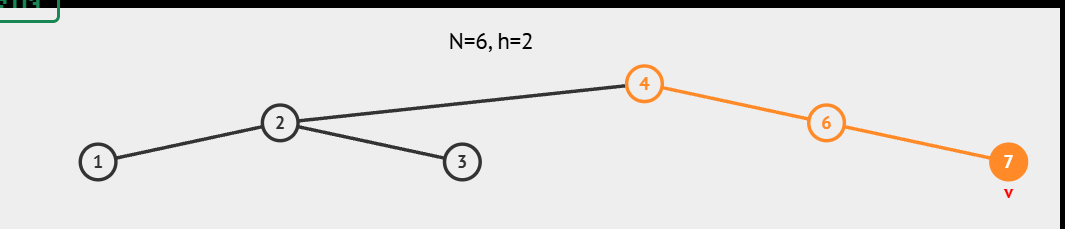

### 제출 과제 4 — github 링크
https://github.com/kimsu012/data_structure.git